In [34]:
import pandas as pd

In [35]:
Data = pd.read_csv("DataEngineer.csv")

Data.head()

,Job Title,Salary Estimate,Job Description,Rating,Company Name,Location,Headquarters,Size,Founded,Type of ownership,Industry,Sector,Revenue,Competitors,Easy Apply
0,Data Engineer,$80K-$150K (Glassdoor est.),Company Description\nSagence is a management a...,4.5,Sagence\n4.5,"New York, NY","Chicago, IL",1 to 50 employees,2009,Company - Private,Consulting,Business Services,$10 to $25 million (USD),"WCI Consulting, PwC",-1
1,Senior Data Engineer (Healthcare Domain experi...,$80K-$150K (Glassdoor est.),"Key Responsibilities\n\n- Architect, build, an...",3.4,Enterprise Integration\n3.4,"New York, NY","Jacksonville, FL",51 to 200 employees,1998,Company - Private,IT Services,Information Technology,$25 to $50 million (USD),-1,-1
2,Data Engineers,$80K-$150K (Glassdoor est.),Overview\n\nJob description\n\nPosition Overvi...,5.0,Maestro Technologies\n5.0,"New York, NY","Trenton, NJ",51 to 200 employees,2003,Company - Private,IT Services,Information Technology,$5 to $10 million (USD),-1,-1
3,Client Trade Support Engineer,$80K-$150K (Glassdoor est.),About the Position\n\n\nThis position will sup...,4.8,Jane Street\n4.8,"New York, NY","New York, NY",501 to 1000 employees,2000,Company - Private,Investment Banking & Asset Management,Finance,Unknown / Non-Applicable,-1,-1
4,Data Engineer,$80K-$150K (Glassdoor est.),Data Engineer\n\nJob Details\nLevel\nExperienc...,3.7,GNY Insurance Companies\n3.7,"New York, NY","New York, NY",201 to 500 employees,1914,Company - Private,Insurance Carriers,Insurance,$100 to $500 million (USD),"Travelers, Chubb, Crum & Forster",True


In [36]:
Data.info()

<class 'pandas.DataFrame'>
RangeIndex: 2528 entries, 0 to 2527
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Job Title          2528 non-null   str    
 1   Salary Estimate    2528 non-null   str    
 2   Job Description    2528 non-null   str    
 3   Rating             2528 non-null   float64
 4   Company Name       2528 non-null   str    
 5   Location           2528 non-null   str    
 6   Headquarters       2528 non-null   str    
 7   Size               2528 non-null   str    
 8   Founded            2528 non-null   int64  
 9   Type of ownership  2528 non-null   str    
 10  Industry           2528 non-null   str    
 11  Sector             2528 non-null   str    
 12  Revenue            2528 non-null   str    
 13  Competitors        2528 non-null   str    
 14  Easy Apply         2528 non-null   str    
dtypes: float64(1), int64(1), str(13)
memory usage: 296.4 KB


In [37]:
Data.describe(include="all")

,Job Title,Salary Estimate,Job Description,Rating,Company Name,Location,Headquarters,Size,Founded,Type of ownership,Industry,Sector,Revenue,Competitors,Easy Apply
count,2528,2528,2528,2528.000000,2528,2528,2528,2528,2528.000000,2528,2528,2528,2528,2528,2528
unique,1260,91,2296,NaN,1457,113,436,9,NaN,14,84,25,14,331,2
top,Data Engineer,$60K-$109K (Glassdoor est.),Organization: Accenture Federal Services\n\nLo...,NaN,Amazon\n3.9,"Houston, TX","New York, NY",10000+ employees,NaN,Company - Private,-1,Information Technology,Unknown / Non-Applicable,-1,-1
freq,469,62,7,NaN,28,199,178,557,NaN,1392,378,890,714,1749,2382
mean,NaN,NaN,NaN,3.379549,NaN,NaN,NaN,NaN,1534.771756,NaN,NaN,NaN,NaN,NaN,NaN
std,NaN,NaN,NaN,1.519254,NaN,NaN,NaN,NaN,830.525022,NaN,NaN,NaN,NaN,NaN,NaN
min,NaN,NaN,NaN,-1.000000,NaN,NaN,NaN,NaN,-1.000000,NaN,NaN,NaN,NaN,NaN,NaN
25%,NaN,NaN,NaN,3.300000,NaN,NaN,NaN,NaN,1864.000000,NaN,NaN,NaN,NaN,NaN,NaN
50%,NaN,NaN,NaN,3.800000,NaN,NaN,NaN,NaN,1990.000000,NaN,NaN,NaN,NaN,NaN,NaN
75%,NaN,NaN,NaN,4.100000,NaN,NaN,NaN,NaN,2003.000000,NaN,NaN,NaN,NaN,NaN,NaN


In [38]:
missing_values = Data.isnull().sum()
missing_values[missing_values > 0]

Series([], dtype: int64)

In [39]:
less = missing_values[missing_values < 1000].index
over = missing_values[missing_values >= 1000].index

In [40]:
numeric_features = Data[less].select_dtypes(include=['number']).columns

Data[numeric_features] = Data[numeric_features].fillna(
    Data[numeric_features].median()
)

In [42]:
categorical_features = Data[less].select_dtypes(include=['object']).columns

for column in categorical_features:
    Data[column] = Data[column].fillna(Data[column].mode()[0])

C:\Users\ADAM FAISAL JABBAR\AppData\Local\Temp\ipykernel_15676\2391664166.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = Data[less].select_dtypes(include=['object']).columns


In [43]:
df = Data.drop(columns=over)

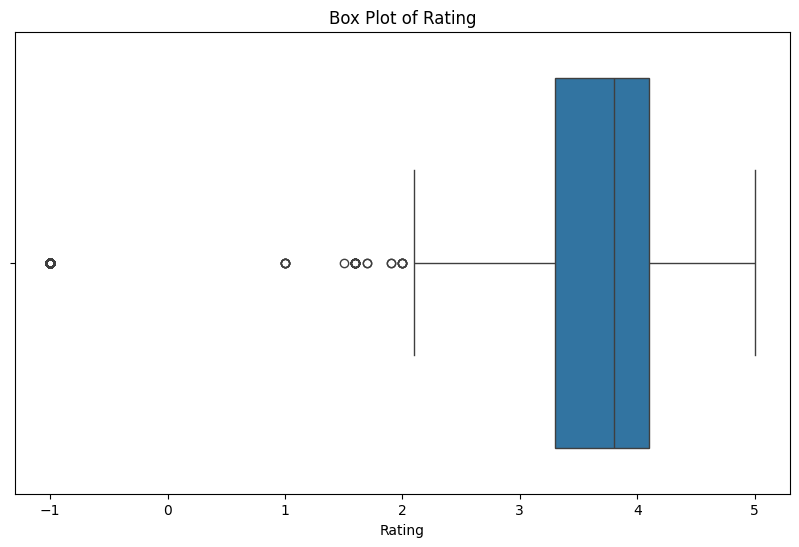

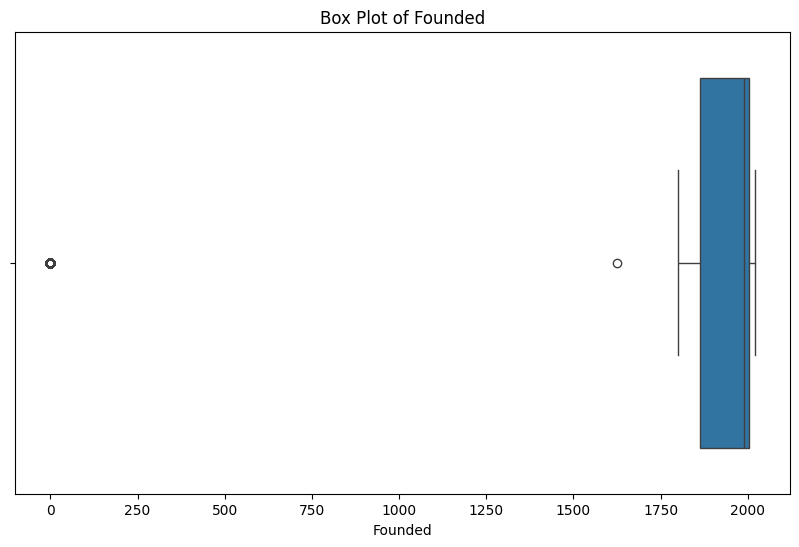

In [44]:
import seaborn as sns
import matplotlib.pyplot as plt

for feature in numeric_features:
    plt.figure(figsize=(10, 6))
    sns.boxplot(x=df[feature])
    plt.title(f'Box Plot of {feature}')
    plt.show()

In [45]:
Q1 = df[numeric_features].quantile(0.25)
Q3 = df[numeric_features].quantile(0.75)
IQR = Q3 - Q1

In [46]:
condition = (
    (df[numeric_features] < (Q1 - 1.5 * IQR)) |
    (df[numeric_features] > (Q3 - 1.5 * IQR))
).any(axis=1)

df_filtered_numeric = df.loc[condition, numeric_features]

categorical_features = df.select_dtypes(include=['object']).columns

df = pd.concat(
    [df_filtered_numeric, df.loc[condition, categorical_features]],
    axis=1
)

C:\Users\ADAM FAISAL JABBAR\AppData\Local\Temp\ipykernel_15676\1868069527.py:8: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = df.select_dtypes(include=['object']).columns


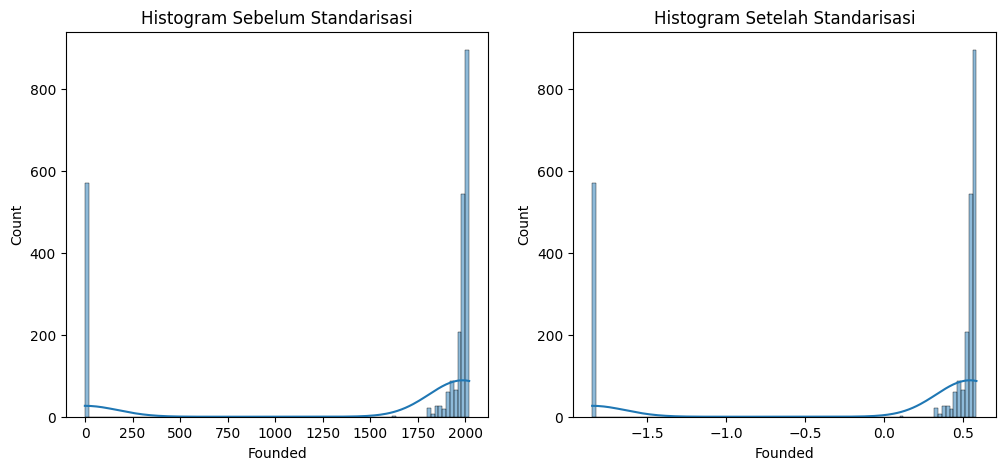

In [50]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
df[numeric_features] = scaler.fit_transform(df[numeric_features])
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
sns.histplot(Data[numeric_features[1]], kde=True)
plt.title("Histogram Sebelum Standarisasi")
plt.subplot(1, 2, 2)
sns.histplot(df[numeric_features[1]], kde=True)
plt.title("Histogram Setelah Standarisasi")
plt.show()



In [51]:
duplicates = df.duplicated()

print("Baris duplikat:")
print(df[duplicates])


Baris duplikat:
        Rating   Founded                            Job Title  \
237   0.671812  0.563885                        Data Engineer   
261  -2.883267 -1.849524                        Data Engineer   
843   0.013464  0.359155              Data Warehouse Engineer   
1294  0.210968  0.553047      Field Services Support Engineer   
2191  0.276803 -1.849524  Data Systems Engineer/Informaticist   
2358  0.013464  0.477176            Big Data Engineer- Hadoop   
2365 -0.315710 -1.849524  Data Engineer - Cognitive Computing   
2366  0.210968  0.521735                    Big Data Engineer   
2373  0.671812  0.573520                    Big Data Engineer   
2374  0.013464  0.520531            Machine Learning Engineer   
2387 -0.249875  0.559068                    Sr. Data Engineer   
2518  1.066821  0.575928             Senior Software Engineer   

                  Salary Estimate  \
237   $95K-$167K (Glassdoor est.)   
261   $95K-$167K (Glassdoor est.)   
843   $79K-$104K (Glassdoor

In [52]:
df = df.drop_duplicates()

print("DataFrame setelah menghapus duplikat:")
print(df)

DataFrame setelah menghapus duplikat:
        Rating   Founded                                          Job Title  \
0     0.737647  0.571111                                      Data Engineer   
1     0.013464  0.557864  Senior Data Engineer (Healthcare Domain experi...   
2     1.066821  0.563885                                     Data Engineers   
3     0.935151  0.560272                      Client Trade Support Engineer   
4     0.210968  0.456703                                      Data Engineer   
...        ...       ...                                                ...   
2523  0.737647 -1.849524                                     Cloud Engineer   
2524 -0.315710  0.551842                                Electrical Engineer   
2525  0.210968 -1.849524                              Sr. Big Data Engineer   
2526  0.079299 -1.849524                     Senior Big Data / ETL Engineer   
2527  0.145133  0.560272                                     Cloud Engineer   

             

In [53]:
category_features = df.select_dtypes(include=['object']).columns
df[category_features]

C:\Users\ADAM FAISAL JABBAR\AppData\Local\Temp\ipykernel_15676\2319133481.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  category_features = df.select_dtypes(include=['object']).columns


,Job Title,Salary Estimate,Job Description,Company Name,Location,Headquarters,Size,Type of ownership,Industry,Sector,Revenue,Competitors,Easy Apply
0,Data Engineer,$80K-$150K (Glassdoor est.),Company Description\nSagence is a management a...,Sagence\n4.5,"New York, NY","Chicago, IL",1 to 50 employees,Company - Private,Consulting,Business Services,$10 to $25 million (USD),"WCI Consulting, PwC",-1
1,Senior Data Engineer (Healthcare Domain experi...,$80K-$150K (Glassdoor est.),"Key Responsibilities\n\n- Architect, build, an...",Enterprise Integration\n3.4,"New York, NY","Jacksonville, FL",51 to 200 employees,Company - Private,IT Services,Information Technology,$25 to $50 million (USD),-1,-1
2,Data Engineers,$80K-$150K (Glassdoor est.),Overview\n\nJob description\n\nPosition Overvi...,Maestro Technologies\n5.0,"New York, NY","Trenton, NJ",51 to 200 employees,Company - Private,IT Services,Information Technology,$5 to $10 million (USD),-1,-1
3,Client Trade Support Engineer,$80K-$150K (Glassdoor est.),About the Position\n\n\nThis position will sup...,Jane Street\n4.8,"New York, NY","New York, NY",501 to 1000 employees,Company - Private,Investment Banking & Asset Management,Finance,Unknown / Non-Applicable,-1,-1
4,Data Engineer,$80K-$150K (Glassdoor est.),Data Engineer\n\nJob Details\nLevel\nExperienc...,GNY Insurance Companies\n3.7,"New York, NY","New York, NY",201 to 500 employees,Company - Private,Insurance Carriers,Insurance,$100 to $500 million (USD),"Travelers, Chubb, Crum & Forster",True
...,...,...,...,...,...,...,...,...,...,...,...,...,...
2523,Cloud Engineer,$76K-$128K (Glassdoor est.),The Expertise You Have Proven expertise in dev...,PMG Global\n4.5,"Westlake, TX","Herndon, VA",1 to 50 employees,Company - Private,Computer Hardware & Software,Information Technology,$1 to $5 million (USD),-1,-1
2524,Electrical Engineer,$76K-$128K (Glassdoor est.),Lockheed Martin is seeking a Circuit and FPGA ...,Albin Engineering Services\n2.9,"Fort Worth, TX","Santa Clara, CA",51 to 200 employees,Company - Private,Staffing & Outsourcing,Business Services,$5 to $10 million (USD),-1,-1
2525,Sr. Big Data Engineer,$76K-$128K (Glassdoor est.),Posting Title Principal Data Engineer (Contrac...,Cincinnati Bell Technology Solutions\n3.7,"Irving, TX","Cincinnati, OH",501 to 1000 employees,Company - Private,IT Services,Information Technology,$100 to $500 million (USD),-1,-1
2526,Senior Big Data / ETL Engineer,$76K-$128K (Glassdoor est.),"Your Opportunity\n\nCharles Schwab & Co., Inc ...",Schwab\n3.5,"Westlake, TX","Dettenheim, Germany",Unknown,Company - Public,-1,-1,Unknown / Non-Applicable,-1,-1


In [ ]:
df_one_hot = pd.get_dummies(df, columns=category_features)
df_one_hot

,Id,GameID,Bet,BustedAt,Username_----------------,Username_--dilib--,Username_-31337-,Username_-Nothing-,Username_-Tachyon,Username_-Y-,...,PlayDate_2016-12-10T19:59:08Z,PlayDate_2016-12-10T20:00:22Z,PlayDate_2016-12-10T20:00:45Z,PlayDate_2016-12-10T20:01:01Z,PlayDate_2016-12-10T20:03:00Z,PlayDate_2016-12-10T20:03:34Z,PlayDate_2016-12-10T20:04:51Z,PlayDate_2016-12-10T20:07:15Z,PlayDate_2016-12-10T20:08:25Z,PlayDate_2016-12-10T20:09:12Z
0,0.085740,0.061513,-0.095599,-0.007290,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1,-0.367433,-0.470130,-0.095664,-0.013122,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2,0.263460,0.269268,-0.095631,-0.011630,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3,1.570718,1.581432,-0.095435,-0.012926,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
4,0.574771,0.618441,-0.094130,-0.012363,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49995,1.005975,1.026860,-0.095631,-0.010223,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
49996,-1.553658,-1.466770,0.002112,-0.010027,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
49997,0.794792,0.840640,-0.095729,-0.013412,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
49998,0.842534,0.885320,-0.093543,0.001884,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


In [54]:
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()
df_lencoder = pd.DataFrame(df)

for col in category_features:
    df_lencoder[col] = label_encoder.fit_transform(df[col])

df_lencoder

,Rating,Founded,Job Title,Salary Estimate,Job Description,Company Name,Location,Headquarters,Size,Type of ownership,Industry,Sector,Revenue,Competitors,Easy Apply
0,0.737647,0.571111,235,72,409,1073,71,100,1,2,18,6,2,314,0
1,0.013464,0.557864,876,72,1215,446,71,193,7,2,43,13,6,0,0
2,1.066821,0.563885,372,72,1419,787,71,396,7,2,43,13,8,0,0
3,0.935151,0.560272,147,72,137,691,71,271,6,2,48,10,13,0,0
4,0.210968,0.456703,235,72,474,514,71,271,4,2,46,14,4,306,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2523,0.737647,-1.849524,156,65,1924,929,109,181,1,2,16,13,1,0,0
2524,-0.315710,0.551842,465,65,1270,64,42,357,7,2,70,6,8,0,0
2525,0.210968,-1.849524,1116,65,1581,271,52,101,6,2,43,13,4,0,0
2526,0.079299,-1.849524,854,65,2239,1081,109,132,8,3,0,0,13,0,0


In [55]:
#Praktek EDA dan ExDA
df_lencoder.head()


,Rating,Founded,Job Title,Salary Estimate,Job Description,Company Name,Location,Headquarters,Size,Type of ownership,Industry,Sector,Revenue,Competitors,Easy Apply
0,0.737647,0.571111,235,72,409,1073,71,100,1,2,18,6,2,314,0
1,0.013464,0.557864,876,72,1215,446,71,193,7,2,43,13,6,0,0
2,1.066821,0.563885,372,72,1419,787,71,396,7,2,43,13,8,0,0
3,0.935151,0.560272,147,72,137,691,71,271,6,2,48,10,13,0,0
4,0.210968,0.456703,235,72,474,514,71,271,4,2,46,14,4,306,1


In [56]:
missing_values = df_lencoder.isnull().sum()
missing_percentage = (missing_values / len(df_lencoder)) *100

missing_data = pd.DataFrame({
    'Missing_Values': missing_values,
    'Percentage': missing_percentage 
}).sort_values(by='Missing_Values', ascending=False)

missing_data[missing_data['Missing_Values']> 0]

,Missing_Values,Percentage


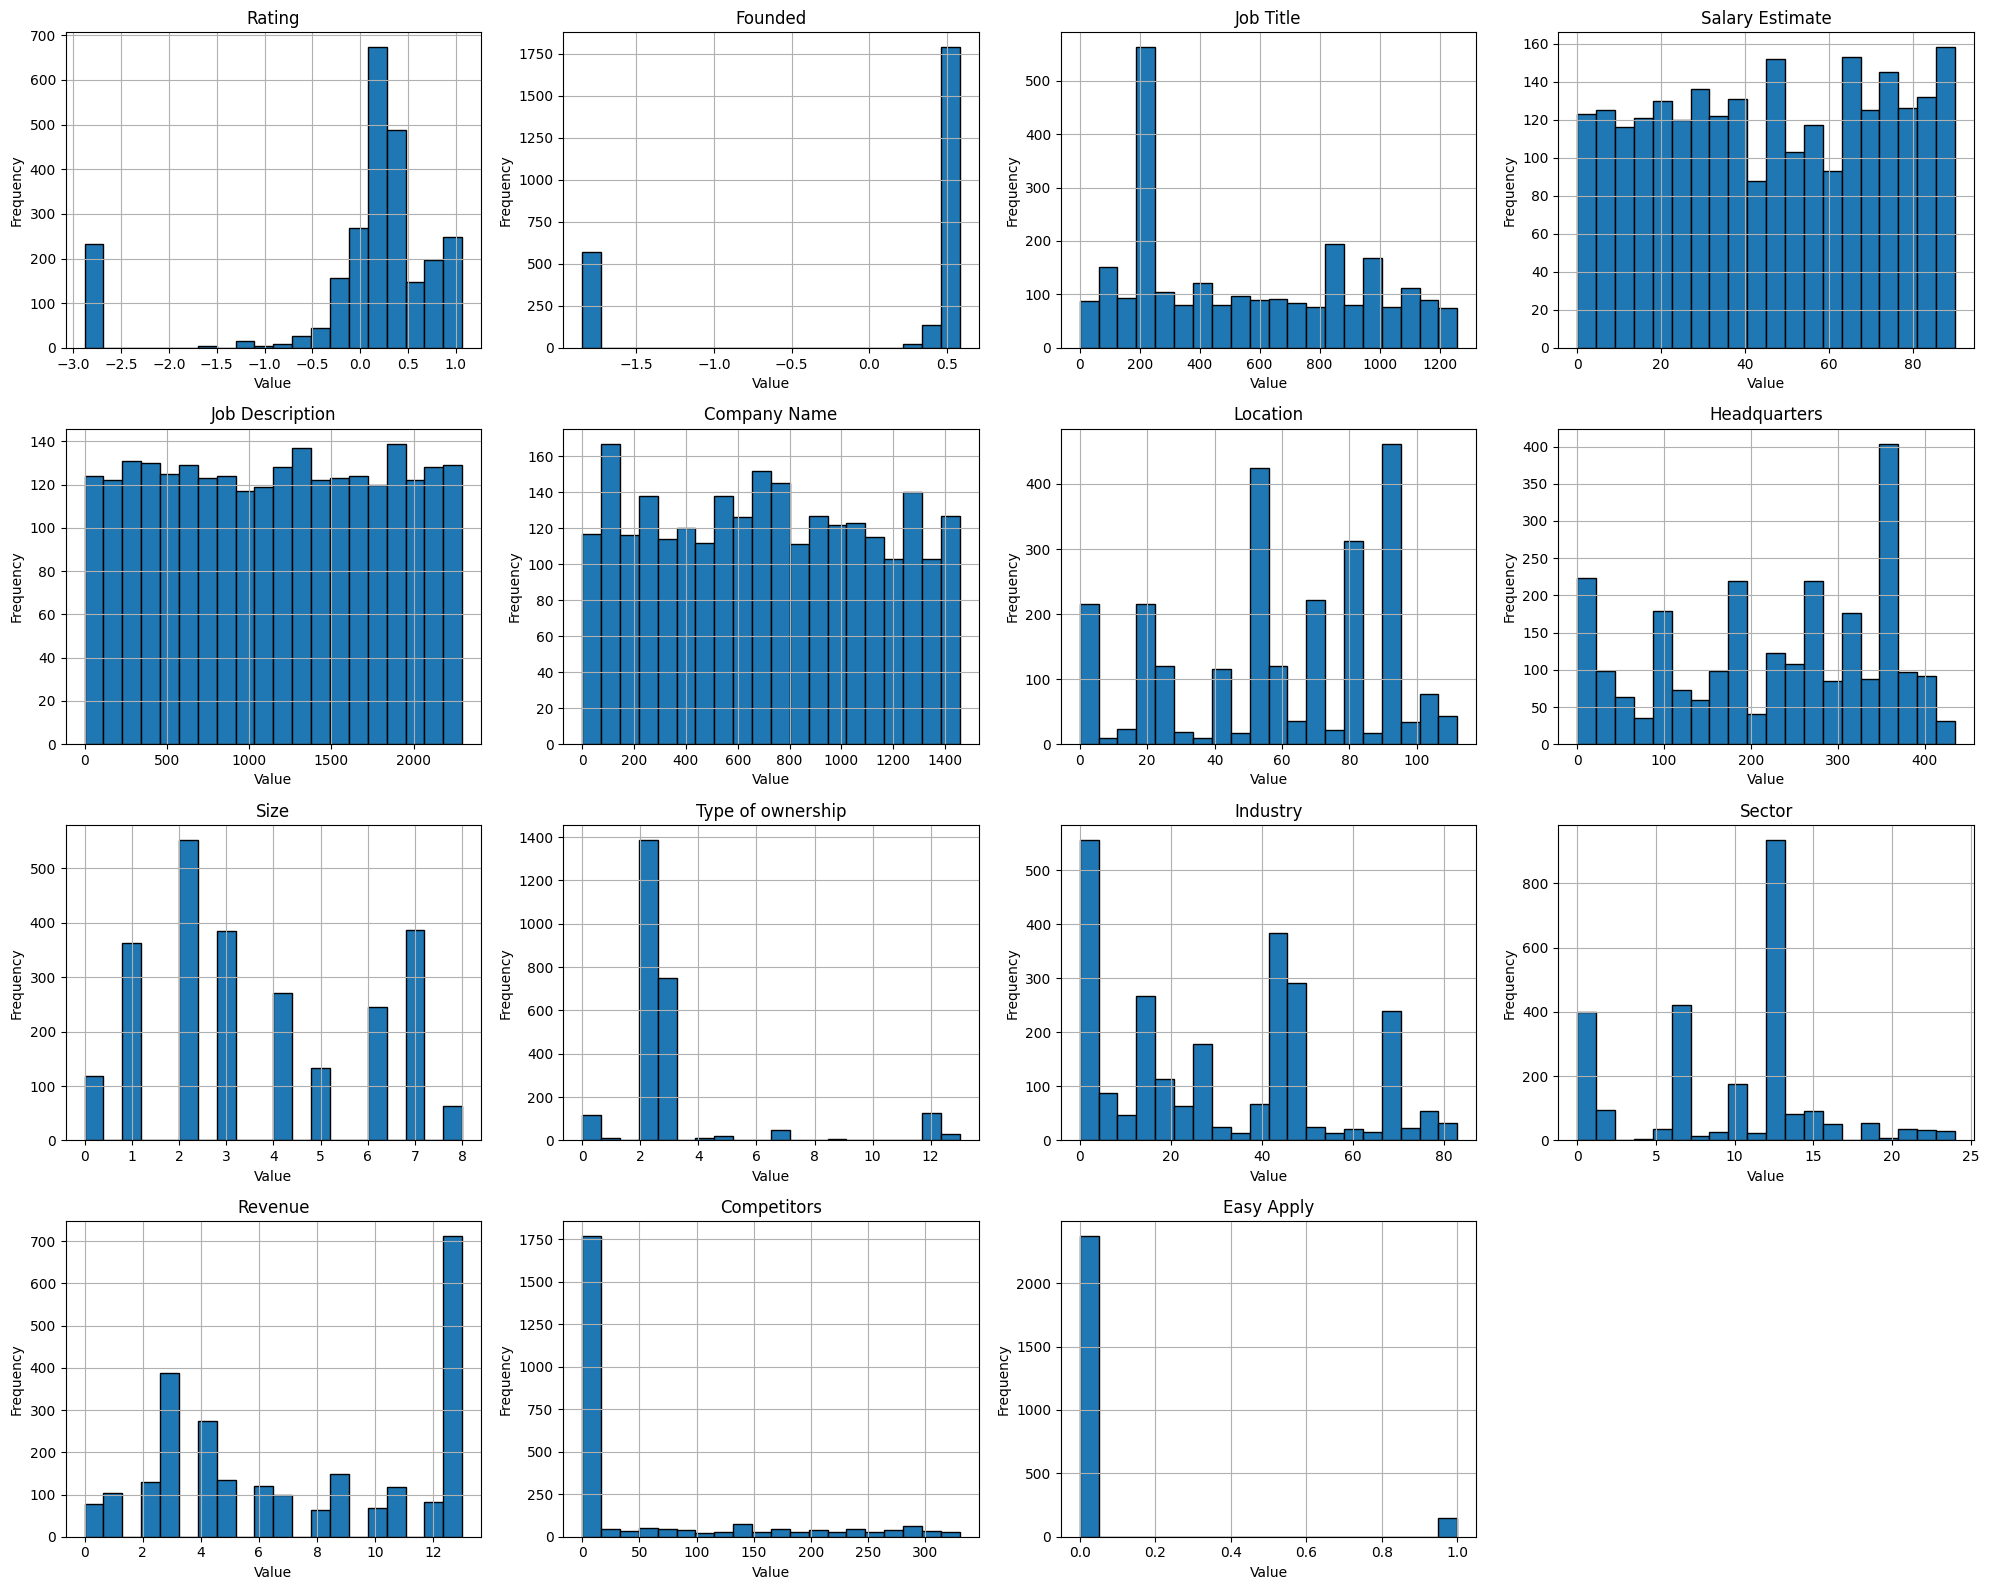

In [57]:
num_vars = df_lencoder.shape[1]

n_cols = 4
n_rows = -(-num_vars // n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, n_rows * 4))
axes = axes.flatten()

for i, column in enumerate(df_lencoder.columns):
    df_lencoder[column].hist(ax=axes[i], bins=20, edgecolor='black')
    axes[i].set_title(column)
    axes[i].set_xlabel('Value')
    axes[i].set_ylabel('Frequency')


for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])


plt.tight_layout()
plt.show()


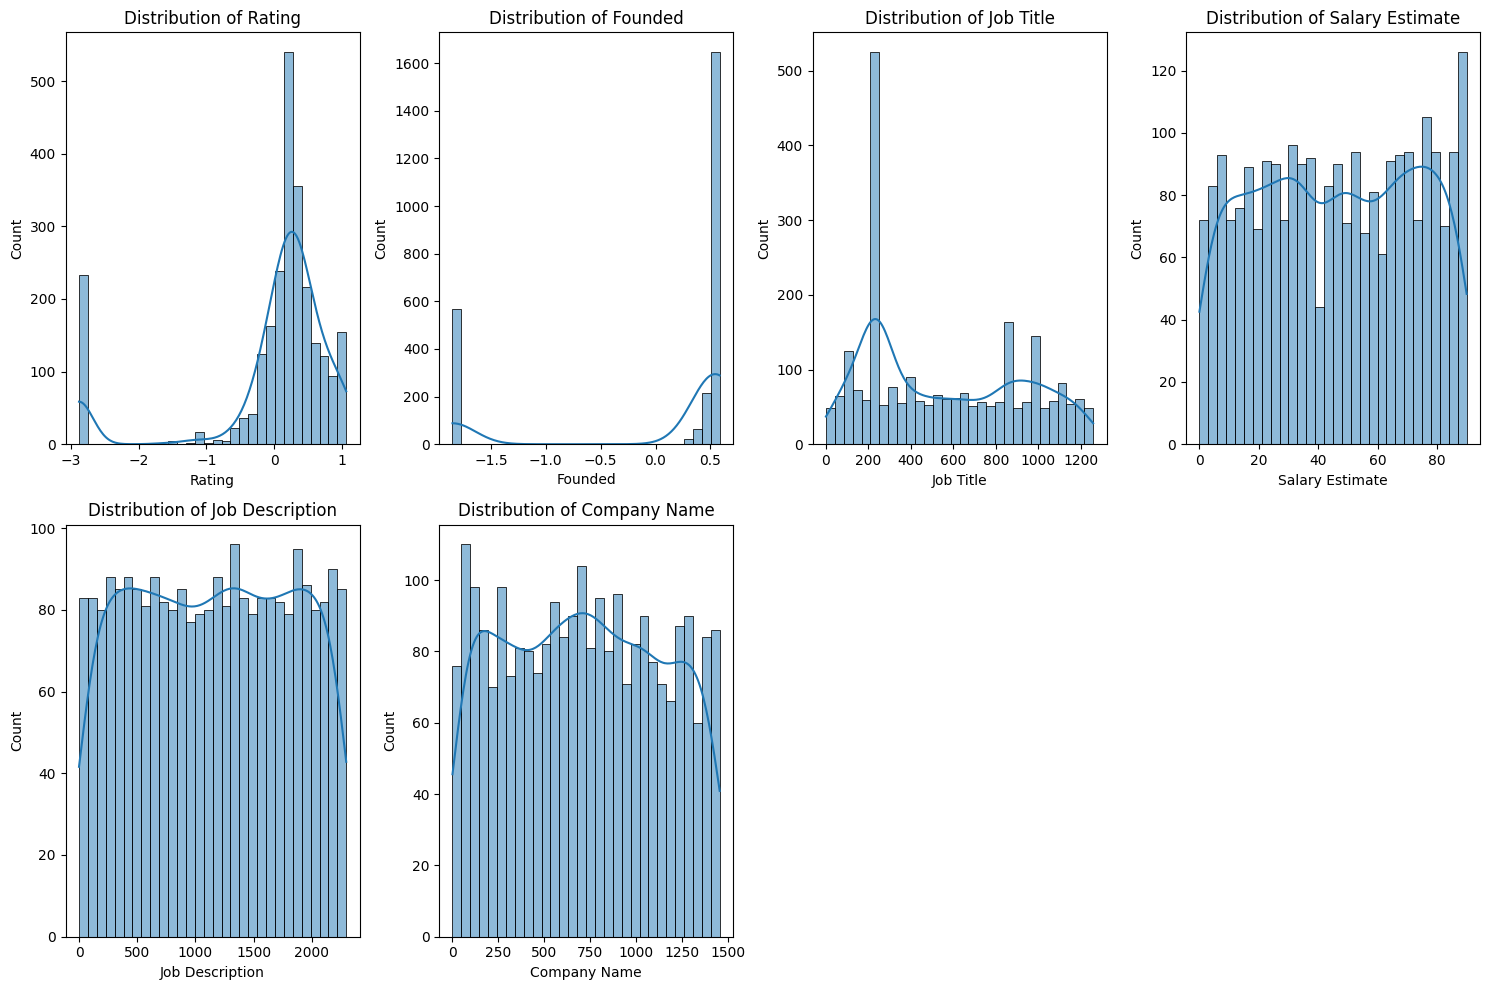

In [58]:
columns_to_plot = [
    'Rating',
    'Founded',
    'Job Title',
    'Salary Estimate',
    'Job Description',
    'Company Name'
]

plt.figure(figsize=(15, 10))

for i, column in enumerate(columns_to_plot, 1):

    plt.subplot(2, 4, i)

    sns.histplot(
        df_lencoder[column],
        kde=True,
        bins=30
    )

    plt.title(f'Distribution of {column}')

plt.tight_layout()
plt.show()

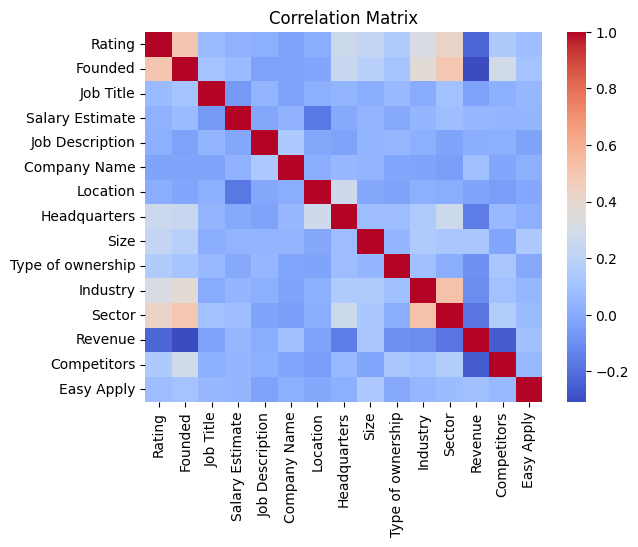

In [59]:
plt.Figure(figsize=(12,10))
correlation_matrix = df_lencoder.corr()

sns.heatmap(correlation_matrix, annot=False, cmap='coolwarm', vmax=1)
plt.title('Correlation Matrix')
plt.show()

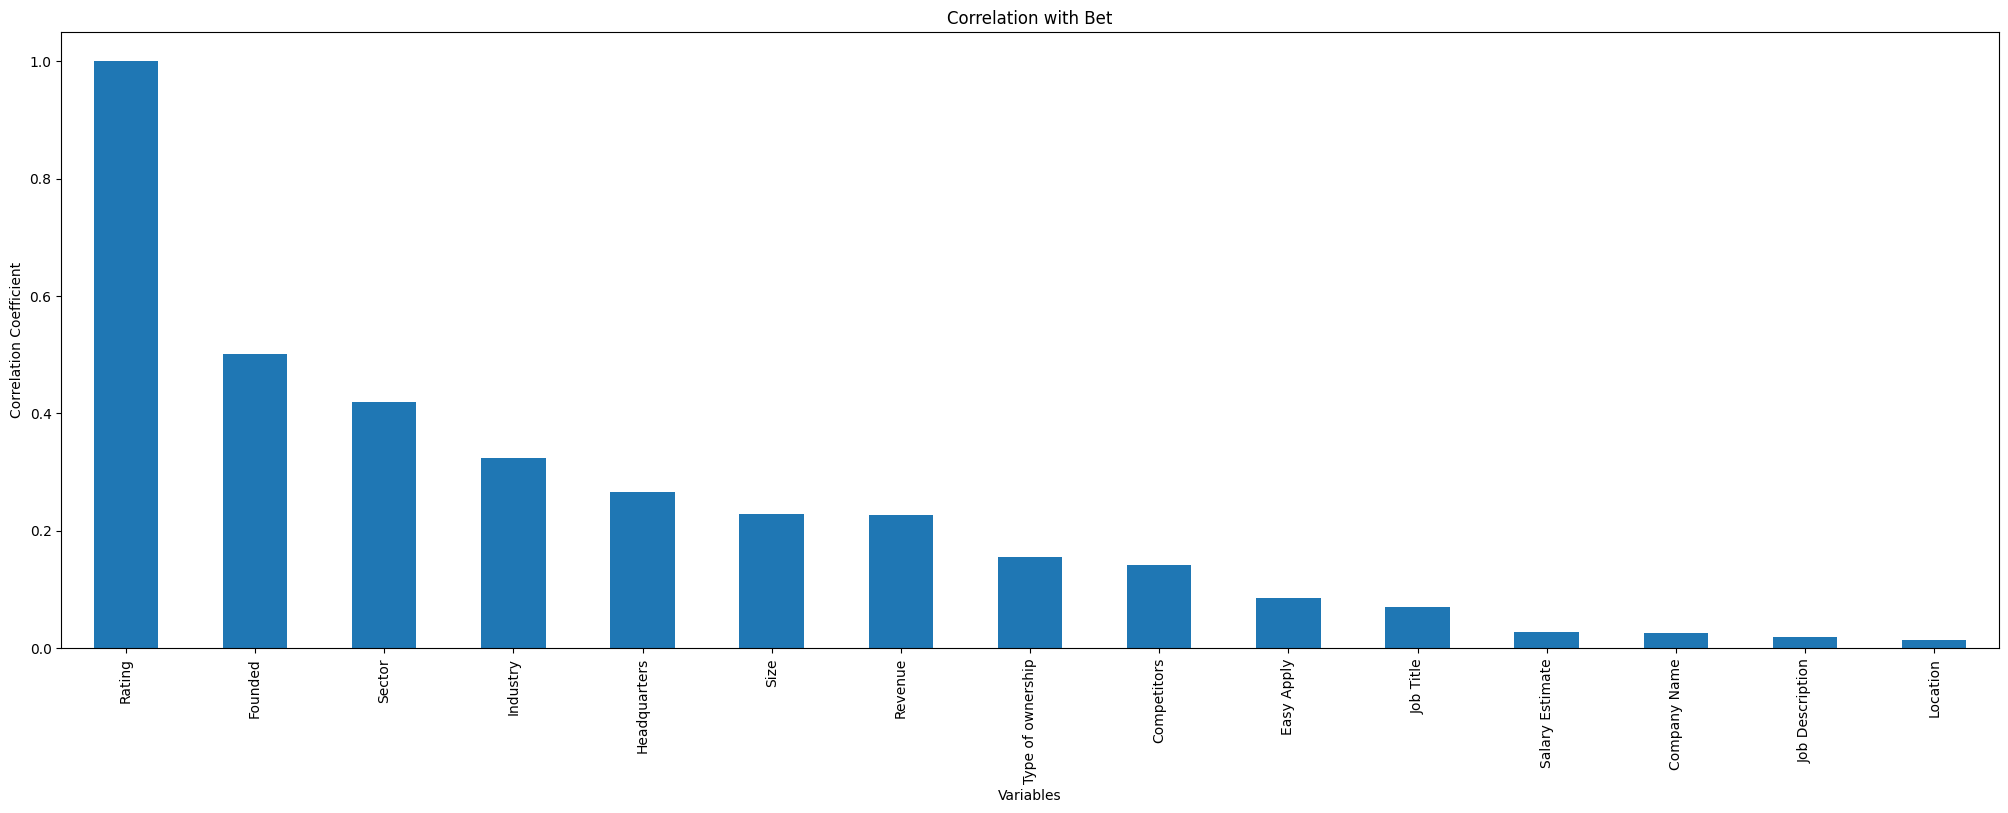

In [60]:
target_corr = df_lencoder.corr()['Rating']

target_corr_sorted = target_corr.abs().sort_values(ascending=False)

plt.figure(figsize=(25, 8))

target_corr_sorted.plot(kind='bar')

plt.title('Correlation with Bet')

plt.xlabel('Variables')

plt.ylabel('Correlation Coefficient')

plt.show()